In [13]:
#Dataset Download from Kaggle API

!pip install -q kagglehub scikit-learn pandas numpy matplotlib

import kagglehub
import os
import pandas as pd


path = kagglehub.dataset_download("shanegerami/ai-vs-human-text")
print(" Dataset downloaded to:", path)

csv_path = None
for root, dirs, files in os.walk(path):
    for f in files:
        if f.lower().endswith(".csv"):
            csv_path = os.path.join(root, f)

if csv_path is None:
    raise FileNotFoundError("CSV not found!")

print("Found CSV:", csv_path)

df = pd.read_csv(csv_path)

print("\nDataset loaded")
print(df.head())
print("\nClass distribution:  0 (Human), 1(AI generated)")
print(df["generated"].value_counts())

 Dataset downloaded to: C:\Users\xhani\.cache\kagglehub\datasets\shanegerami\ai-vs-human-text\versions\1
Found CSV: C:\Users\xhani\.cache\kagglehub\datasets\shanegerami\ai-vs-human-text\versions\1\AI_Human.csv

Dataset loaded
                                                text  generated
0  Cars. Cars have been around since they became ...        0.0
1  Transportation is a large necessity in most co...        0.0
2  "America's love affair with it's vehicles seem...        0.0
3  How often do you ride in a car? Do you drive a...        0.0
4  Cars are a wonderful thing. They are perhaps o...        0.0

Class distribution:  0 (Human), 1(AI generated)
generated
0.0    305797
1.0    181438
Name: count, dtype: int64


In [14]:
# Quick check if there is any missing or duplicate in the big dataset
num_duplicates = df.duplicated(subset="text").sum()

print("Number of duplicate text entries:", num_duplicates)
missing= df.isnull().sum()
print(missing)


Number of duplicate text entries: 0
text         0
generated    0
dtype: int64


In [15]:
#Balancing the dataset

ai_written=df[df["generated"]== 1].sample(5000, random_state=42)
human_written = df[df["generated"] == 0].sample(5000, random_state=42)

balanced_dataset=pd.concat([ai_written, human_written]).sample(frac=1,random_state=42)

print(balanced_dataset["generated"].value_counts())
print(balanced_dataset.head())


generated
0.0    5000
1.0    5000
Name: count, dtype: int64
                                                     text  generated
269265  Dear Principal,\n\nWe have been hearing quite ...        0.0
327273   Dear [State Senator],\n\nI am writing to expr...        1.0
167398  As high school students, we are constantly bom...        1.0
291678  Hi, I'm a 6th garden and I think zoos ANE Near...        1.0
457139  Sure, jar's my attempt at writing an essay as ...        1.0


In [16]:
#Train/Test Split

from sklearn.model_selection import train_test_split

X=balanced_dataset["text"]
y=balanced_dataset["generated"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


In [17]:
#Feature Extraction using text statistics

import numpy as np

def text_extraction(text_statistics):
    new_features=[]
    for text in text_statistics:
        if type(text)== str:
            word=text.split()
            nr_words=len(word)
            nr_chars=len(text)
            unique_words=len(set(word))
            if nr_words:
                avg_word_length=nr_chars/nr_words
            else: 
                avg_word_length=0
            if nr_chars:
                punctuation_ratio= sum(char in".,;:!?'" for char in text) / nr_chars
            else:
                punctuation_ratio=0
            if nr_chars:
                capital_ratio= sum(char.isupper() for char in text) / nr_chars
            else:
                capital_ratio=0
            if nr_chars:
                digit_ratio= sum(char.isdigit() for char in text) / nr_chars
            else:
                digit_ratio=0   
            if nr_words:
                type_token_r=unique_words/nr_words
            else:    
                type_token_r=0

            new_features.append ([nr_words, nr_chars, avg_word_length, punctuation_ratio, capital_ratio, digit_ratio, type_token_r])  

    return np.array(new_features) 

X_train_new_f=text_extraction(X_train)
X_test_new_f=text_extraction(X_test)

print("New training features: ",X_train_new_f)
print("\nNew testing features: ",X_test_new_f)

New training features:  [[3.38000000e+02 1.71000000e+03 5.05917160e+00 ... 8.18713450e-03
  0.00000000e+00 5.00000000e-01]
 [3.29000000e+02 1.96400000e+03 5.96960486e+00 ... 1.32382892e-02
  0.00000000e+00 5.13677812e-01]
 [2.16000000e+02 1.20500000e+03 5.57870370e+00 ... 1.32780083e-02
  4.14937759e-03 6.06481481e-01]
 ...
 [1.69000000e+02 9.37000000e+02 5.54437870e+00 ... 8.53788687e-03
  0.00000000e+00 5.26627219e-01]
 [6.19000000e+02 3.60800000e+03 5.82875606e+00 ... 2.10643016e-02
  5.54323725e-04 5.08885299e-01]
 [7.38000000e+02 4.19300000e+03 5.68157182e+00 ... 9.30121631e-03
  0.00000000e+00 3.78048780e-01]]

New testing features:  [[2.54000000e+02 1.43100000e+03 5.63385827e+00 ... 1.39762404e-02
  2.09643606e-03 6.33858268e-01]
 [4.33000000e+02 2.63800000e+03 6.09237875e+00 ... 7.58150114e-03
  0.00000000e+00 4.06466513e-01]
 [3.88000000e+02 2.36300000e+03 6.09020619e+00 ... 1.31189166e-02
  0.00000000e+00 4.20103093e-01]
 ...
 [6.73000000e+02 4.39400000e+03 6.52897474e+00 ...

In [18]:
#Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt


depth_testing=[1,2,3,5,10,None]
leaves=[1,2,5,10,20]
criterion="gini"
accuracy_arr=[]
for d in depth_testing:
    for l in leaves:
        tree = DecisionTreeClassifier(criterion=criterion,max_depth=d,min_samples_leaf=l,random_state=42)

        tree.fit(X_train_new_f,y_train)
        preds = tree.predict(X_test_new_f)

        accuracy = accuracy_score(y_test, preds)  
        accuracy_arr.append(accuracy)  
        print(
                f"Criterion={criterion} | "
                f"Depth={d} | "
                f"Leaf={l} | "
                f"Accuracy={accuracy:.4f}"
            )    



Criterion=gini | Depth=1 | Leaf=1 | Accuracy=0.7505
Criterion=gini | Depth=1 | Leaf=2 | Accuracy=0.7505
Criterion=gini | Depth=1 | Leaf=5 | Accuracy=0.7505
Criterion=gini | Depth=1 | Leaf=10 | Accuracy=0.7505
Criterion=gini | Depth=1 | Leaf=20 | Accuracy=0.7505
Criterion=gini | Depth=2 | Leaf=1 | Accuracy=0.7800
Criterion=gini | Depth=2 | Leaf=2 | Accuracy=0.7800
Criterion=gini | Depth=2 | Leaf=5 | Accuracy=0.7800
Criterion=gini | Depth=2 | Leaf=10 | Accuracy=0.7800
Criterion=gini | Depth=2 | Leaf=20 | Accuracy=0.7800
Criterion=gini | Depth=3 | Leaf=1 | Accuracy=0.7885
Criterion=gini | Depth=3 | Leaf=2 | Accuracy=0.7885
Criterion=gini | Depth=3 | Leaf=5 | Accuracy=0.7885
Criterion=gini | Depth=3 | Leaf=10 | Accuracy=0.7885
Criterion=gini | Depth=3 | Leaf=20 | Accuracy=0.7880
Criterion=gini | Depth=5 | Leaf=1 | Accuracy=0.8470
Criterion=gini | Depth=5 | Leaf=2 | Accuracy=0.8465
Criterion=gini | Depth=5 | Leaf=5 | Accuracy=0.8460
Criterion=gini | Depth=5 | Leaf=10 | Accuracy=0.8495
Crite

Criterion=gini | Depth=1 |Leaf= 1 | Accuracy=0.7505
Criterion=gini | Depth=2 |Leaf= 1 | Accuracy=0.7800
Criterion=gini | Depth=3 |Leaf= 1 | Accuracy=0.7885
Criterion=gini | Depth=5 |Leaf= 1 | Accuracy=0.8470
Criterion=gini | Depth=10 |Leaf= 1 | Accuracy=0.8650
Criterion=gini | Depth=None |Leaf= 1 | Accuracy=0.8430


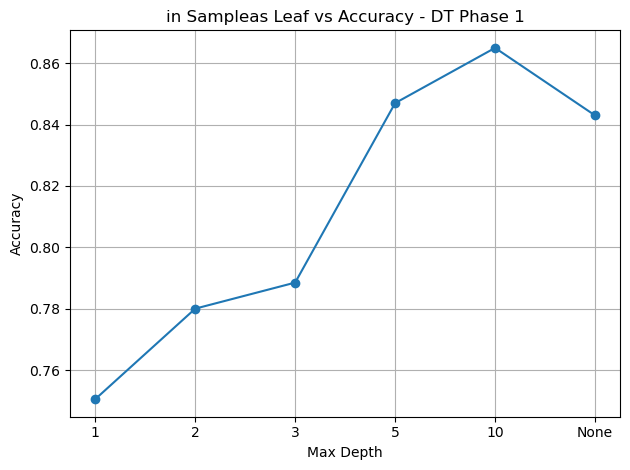

Criterion= gini | Depth=None | Leaf=1 | Accuracy=0.8430
Criterion= gini | Depth=None | Leaf=2 | Accuracy=0.8400
Criterion= gini | Depth=None | Leaf=5 | Accuracy=0.8460
Criterion= gini | Depth=None | Leaf=10 | Accuracy=0.8595
Criterion= gini | Depth=None | Leaf=20 | Accuracy=0.8665
Criterion= gini | Depth=None | Leaf=50 | Accuracy=0.8630


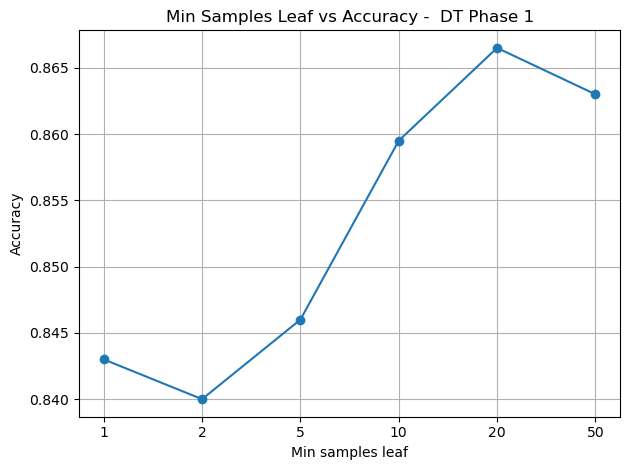

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt


depth_testing=[1,2,3,5,10,None]
leaves=[1,2,5,10,20,50]
criterion="gini"
accuracy_arr=[]
for d in depth_testing:
    
    tree = DecisionTreeClassifier(criterion="gini",max_depth=d,min_samples_leaf=1,random_state=42)

    tree.fit(X_train_new_f,y_train)
    preds = tree.predict(X_test_new_f)

    accuracy = accuracy_score(y_test, preds)  
    accuracy_arr.append(accuracy)  
    print(f"Criterion=gini | Depth={d} |Leaf= 1 | Accuracy={accuracy:.4f}")    

plt.figure()
plt.plot([str(d) for d in depth_testing],accuracy_arr,marker="o")
plt.title("in Sampleas Leaf vs Accuracy - DT Phase 1")
plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

accuracy_arr1=[]
for l in leaves:
    tree = DecisionTreeClassifier(criterion="gini",max_depth=None,min_samples_leaf=l,random_state=42)

    tree.fit(X_train_new_f,y_train)
    preds = tree.predict(X_test_new_f)

    accuracy = accuracy_score(y_test, preds)  
    accuracy_arr1.append(accuracy)  
    print(f"Criterion= gini | Depth=None | Leaf={l} | Accuracy={accuracy:.4f}")    

plt.figure()
plt.plot([str(l) for l in leaves],accuracy_arr1,marker="o")
plt.title("Min Samples Leaf vs Accuracy -  DT Phase 1")
plt.xlabel("Min samples leaf")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
#Random Forest

from sklearn.ensemble import RandomForestClassifier

nr_trees=[10,50,100,250,500]
leaves=[1,2,5,10,20]

for nr in nr_trees:
    for l in leaves:   
        forest=RandomForestClassifier(n_estimators=nr,criterion='gini',max_depth=None,min_samples_leaf=l,random_state=42)
        forest.fit(X_train_new_f,y_train)
        rf_preds=forest.predict(X_test_new_f)
        rf_acc=accuracy_score(y_test,rf_preds)
        print(f" Nr of trees:{nr}, Nr of leaves:{l} Acc: {rf_acc}")

 Nr of trees:10, Nr of leaves:1 Acc: 0.885
 Nr of trees:10, Nr of leaves:2 Acc: 0.877
 Nr of trees:10, Nr of leaves:5 Acc: 0.8775
 Nr of trees:10, Nr of leaves:10 Acc: 0.8775
 Nr of trees:10, Nr of leaves:20 Acc: 0.879
 Nr of trees:50, Nr of leaves:1 Acc: 0.883
 Nr of trees:50, Nr of leaves:2 Acc: 0.883
 Nr of trees:50, Nr of leaves:5 Acc: 0.8845
 Nr of trees:50, Nr of leaves:10 Acc: 0.88
 Nr of trees:50, Nr of leaves:20 Acc: 0.878
 Nr of trees:100, Nr of leaves:1 Acc: 0.8885
 Nr of trees:100, Nr of leaves:2 Acc: 0.888
 Nr of trees:100, Nr of leaves:5 Acc: 0.8845
 Nr of trees:100, Nr of leaves:10 Acc: 0.8815
 Nr of trees:100, Nr of leaves:20 Acc: 0.876
 Nr of trees:250, Nr of leaves:1 Acc: 0.893
 Nr of trees:250, Nr of leaves:2 Acc: 0.8925
 Nr of trees:250, Nr of leaves:5 Acc: 0.884
 Nr of trees:250, Nr of leaves:10 Acc: 0.882
 Nr of trees:250, Nr of leaves:20 Acc: 0.8775
 Nr of trees:500, Nr of leaves:1 Acc: 0.892
 Nr of trees:500, Nr of leaves:2 Acc: 0.8915
 Nr of trees:500, Nr of le

 Nr of trees:100, Nr of leaves:1 Acc: 0.8885
 Nr of trees:100, Nr of leaves:2 Acc: 0.888
 Nr of trees:100, Nr of leaves:5 Acc: 0.8845
 Nr of trees:100, Nr of leaves:10 Acc: 0.8815
 Nr of trees:100, Nr of leaves:20 Acc: 0.876


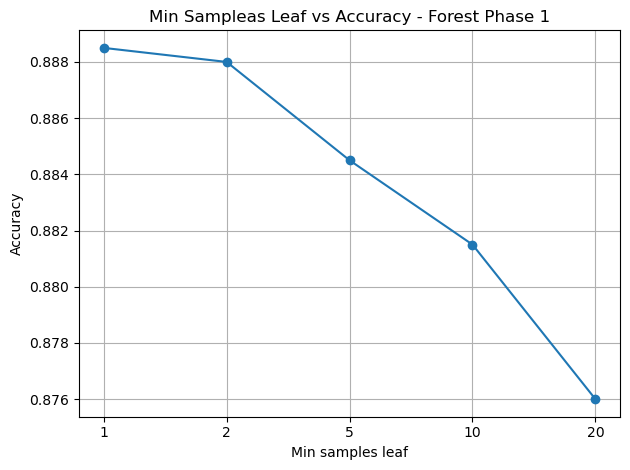

 Nr of trees:10, Nr of leaves:1 Acc: 0.885
 Nr of trees:50, Nr of leaves:1 Acc: 0.883
 Nr of trees:100, Nr of leaves:1 Acc: 0.8885
 Nr of trees:250, Nr of leaves:1 Acc: 0.893
 Nr of trees:500, Nr of leaves:1 Acc: 0.892


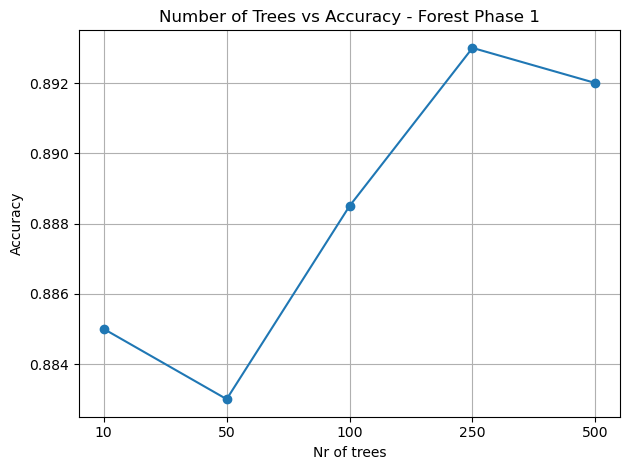

In [ ]:
from sklearn.ensemble import RandomForestClassifier

nr_trees=[10,50,100,250,500]
leaves=[1,2,5,10,20]
accuracy_rf=[]
accuracy_rf2=[]


for l in leaves:   
    forest=RandomForestClassifier(n_estimators=100,criterion='gini',max_depth=None,min_samples_leaf=l,random_state=42)
    forest.fit(X_train_new_f,y_train)
    rf_preds=forest.predict(X_test_new_f)
    rf_acc=accuracy_score(y_test,rf_preds)
    accuracy_rf.append(rf_acc)
    print(f" Nr of trees:100, Nr of leaves:{l} Acc: {rf_acc}")

plt.figure()
plt.plot([str(l) for l in leaves],accuracy_rf,marker="o")
plt.title("Min Samples Leaf vs Accuracy - Forest Phase 1")
plt.xlabel("Min samples leaf")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

for no in nr_trees:   
    forest=RandomForestClassifier(n_estimators=no,criterion='gini',max_depth=None,min_samples_leaf=1,random_state=42)
    forest.fit(X_train_new_f,y_train)
    rf_preds=forest.predict(X_test_new_f)
    rf_acc=accuracy_score(y_test,rf_preds)
    accuracy_rf2.append(rf_acc)
    print(f" Nr of trees:{no}, Nr of leaves:1 Acc: {rf_acc}")

plt.figure()
plt.plot([str(no) for no in nr_trees],accuracy_rf2,marker="o")
plt.title("Number of Trees vs Accuracy - Forest Phase 1")
plt.xlabel("Nr of trees")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
#SVM

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

st_scaler=StandardScaler()
X_train_scaled=st_scaler.fit_transform(X_train_new_f)
X_test_scaled=st_scaler.fit_transform(X_test_new_f)

kernel_exp=['linear','poly','rbf']
c_regularizer=[0.01,0.1,1,5,10]
gamma_exp=['scale',0.1]

print("SVM Parameter tuning")
for k in kernel_exp:
    for c in c_regularizer:    
        for g in gamma_exp:    
            
            svm = SVC(kernel=k, C=c,gamma=g)   
            svm.fit(X_train_scaled, y_train)
            svm_preds = svm.predict(X_test_scaled)

            acc = accuracy_score(y_test, svm_preds)
            print(f"Kernel={k:<6} , C= {c}, Gamma={g}, Accuracy={acc:.4f}")

SVM Parameter tuning
Kernel=linear , C= 0.01, Gamma=scale, Accuracy=0.8515
Kernel=linear , C= 0.01, Gamma=0.1, Accuracy=0.8515
Kernel=linear , C= 0.1, Gamma=scale, Accuracy=0.8530
Kernel=linear , C= 0.1, Gamma=0.1, Accuracy=0.8530
Kernel=linear , C= 1, Gamma=scale, Accuracy=0.8530
Kernel=linear , C= 1, Gamma=0.1, Accuracy=0.8530
Kernel=linear , C= 5, Gamma=scale, Accuracy=0.8515
Kernel=linear , C= 5, Gamma=0.1, Accuracy=0.8515
Kernel=linear , C= 10, Gamma=scale, Accuracy=0.8520
Kernel=linear , C= 10, Gamma=0.1, Accuracy=0.8520
Kernel=poly   , C= 0.01, Gamma=scale, Accuracy=0.8100
Kernel=poly   , C= 0.01, Gamma=0.1, Accuracy=0.8060
Kernel=poly   , C= 0.1, Gamma=scale, Accuracy=0.8515
Kernel=poly   , C= 0.1, Gamma=0.1, Accuracy=0.8225
Kernel=poly   , C= 1, Gamma=scale, Accuracy=0.8620
Kernel=poly   , C= 1, Gamma=0.1, Accuracy=0.8635
Kernel=poly   , C= 5, Gamma=scale, Accuracy=0.8615
Kernel=poly   , C= 5, Gamma=0.1, Accuracy=0.8590
Kernel=poly   , C= 10, Gamma=scale, Accuracy=0.8620
Kerne

SVM Parameter tuning
Kernel=linear , C= 1, Gamma=scale, Accuracy=0.8530
Kernel=poly   , C= 1, Gamma=scale, Accuracy=0.8620
Kernel=rbf    , C= 1, Gamma=scale, Accuracy=0.8820


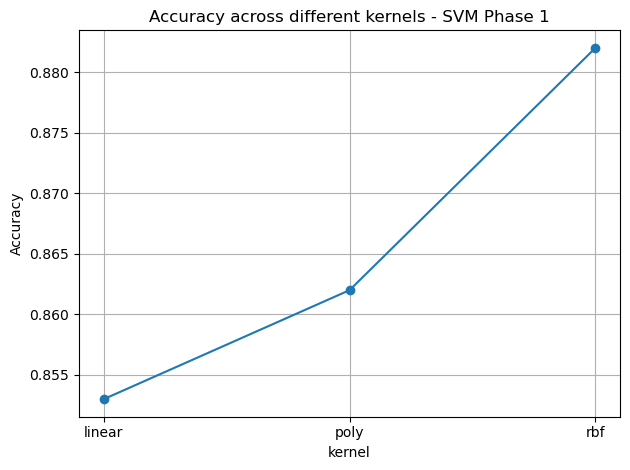

Kernel=rbf    , C= 1, Gamma=scale, Accuracy=0.8525
Kernel=rbf    , C= 1, Gamma=scale, Accuracy=0.8745
Kernel=rbf    , C= 1, Gamma=scale, Accuracy=0.8820
Kernel=rbf    , C= 1, Gamma=scale, Accuracy=0.8815
Kernel=rbf    , C= 1, Gamma=scale, Accuracy=0.8810


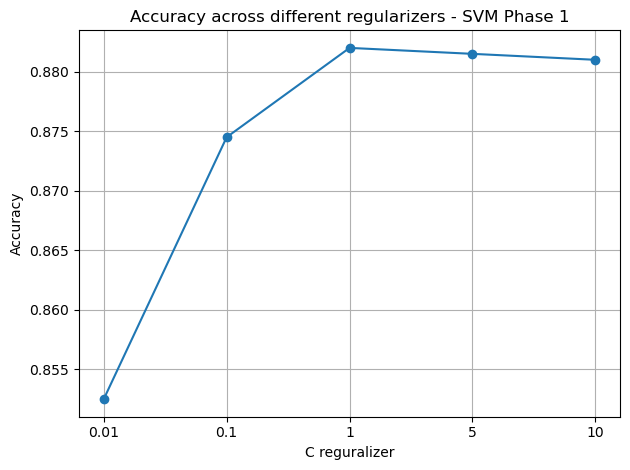

Kernel=rbf    , C= 1, Gamma=scale, Accuracy=0.8650
Kernel=rbf    , C= 1, Gamma=scale, Accuracy=0.8805
Kernel=rbf    , C= 1, Gamma=scale, Accuracy=0.8820


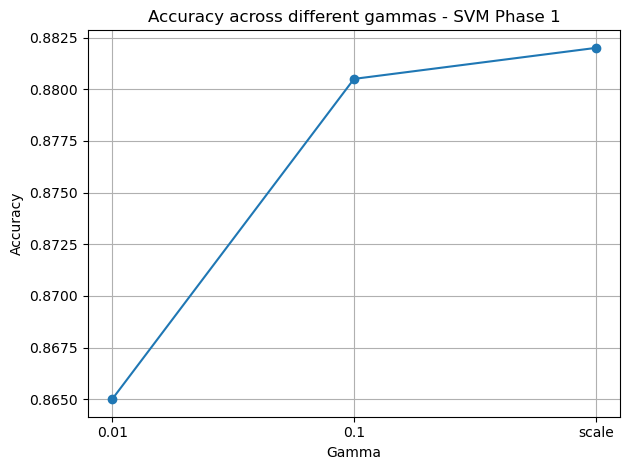

In [23]:
kernel_exp=['linear','poly','rbf']
c_regularizer=[0.01,0.1,1,5,10]
gamma_exp=[0.01,0.1,'scale',]
acc_kernel=[]
acc_c=[]
acc_gamma=[]
print("SVM Parameter tuning")
for k in kernel_exp:
          
    svm = SVC(kernel=k,C=1,gamma='scale')   
    svm.fit(X_train_scaled, y_train)
    svm_preds = svm.predict(X_test_scaled)

    acc = accuracy_score(y_test, svm_preds)
    acc_kernel.append(acc)
    print(f"Kernel={k:<6} , C= 1, Gamma=scale, Accuracy={acc:.4f}")


plt.figure()
plt.title("Accuracy across different kernels - SVM Phase 1")
plt.plot([str(k) for k in kernel_exp],acc_kernel,marker="o")
plt.xlabel("kernel")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

for c in c_regularizer:
          
    svm = SVC(kernel='rbf',C=c,gamma='scale')   
    svm.fit(X_train_scaled, y_train)
    svm_preds = svm.predict(X_test_scaled)

    acc = accuracy_score(y_test, svm_preds)
    acc_c.append(acc)
    print(f"Kernel={k:<6} , C= 1, Gamma=scale, Accuracy={acc:.4f}")

plt.figure()
plt.title("Accuracy across different regularizers - SVM Phase 1")
plt.plot([str(c) for c in c_regularizer],acc_c,marker="o")
plt.xlabel("C reguralizer")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()

for g in gamma_exp:
          
    svm = SVC(kernel='rbf',C=1,gamma=g)   
    svm.fit(X_train_scaled, y_train)
    svm_preds = svm.predict(X_test_scaled)

    acc = accuracy_score(y_test, svm_preds)
    acc_gamma.append(acc)
    print(f"Kernel={k:<6} , C= 1, Gamma=scale, Accuracy={acc:.4f}")

plt.figure()
plt.title("Accuracy across different gammas - SVM Phase 1")
plt.plot([str(g) for g in gamma_exp],acc_gamma,marker="o")
plt.xlabel("Gamma")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.show()